In [1]:
import pandas as pd
import os

In [2]:

# Parameters (double-check values)
weather_year = 2010
FES_year = '2022'
FES_scenario = "LW"
future_year = 2050

# Correct relative path (go up one level from /notebooks to the project root)
path = f"../data/LA_UK/new_version/outputs/heating_profiles/{weather_year}_{FES_year}_{FES_scenario}_{future_year}"

# Optional debug print
print("Checking path:", os.path.abspath(path))
if not os.path.exists(path):
    raise FileNotFoundError(f"❌ Folder not found: {path}")

# Now collect grid IDs
grid_ids = [
    f.replace(f'half_hourly_heat_profile_', '').replace(f'_{weather_year}_{FES_year}_{FES_scenario}_{future_year}.csv', '')
    for f in os.listdir(path)
    if f.endswith('.csv') and f.startswith('half_hourly_heat_profile_')
]


Checking path: c:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\data\LA_UK\new_version\outputs\heating_profiles\2010_2022_LW_2050


In [3]:
from collections import defaultdict
import pandas as pd
import os
# Initialize accumulators
total_demand = None
total_dwellings_per_tech = defaultdict(lambda: pd.Series(0, index=pd.date_range(f"{future_year}-01-01", periods=17520, freq='30min')))

# Load total dwelling counts per grid (you already have this from distributed_heat_tech.csv)
dwelling_df = pd.read_csv("../data/LA_UK/new_version/gird_square_heat_demand.csv")
dwelling_df.set_index("Grid_ID", inplace=True)

# Loop through grid profiles and accumulate
for grid_id in grid_ids:
    try:
        df = pd.read_csv(os.path.join(path, f'half_hourly_heat_profile_{grid_id}_{weather_year}_{FES_year}_{FES_scenario}_{future_year}.csv'), index_col=0, parse_dates=True)

        # Initialize total_demand if not set
        if total_demand is None:
            total_demand = df.copy()
        else:
            total_demand += df

        # Add dwellings per tech for this grid
        for tech in ['ASHP', 'GSHP']:
            if tech in df.columns and tech in dwelling_df.columns:
                total_dwellings_per_tech[tech] += dwelling_df.loc[grid_id, tech]

    except Exception as e:
        print(f"❌ Could not process {grid_id}: {e}")


In [4]:
per_dwelling_profiles = pd.DataFrame(index=total_demand.index)

for tech in ['ASHP', 'GSHP']:
    per_dwelling_profiles[tech] = total_demand[tech] / total_dwellings_per_tech[tech].values
per_dwelling_profiles

,ASHP,GSHP
2050-01-01 00:00:00,1.282660,1.480251
2050-01-01 00:30:00,1.305079,1.508903
2050-01-01 01:00:00,1.343866,1.552269
2050-01-01 01:30:00,1.369854,1.581965
2050-01-01 02:00:00,1.416504,1.628127
...,...,...
2050-12-31 21:30:00,1.399585,1.431404
2050-12-31 22:00:00,1.233179,1.293944
2050-12-31 22:30:00,1.069673,1.159329
2050-12-31 23:00:00,0.947152,1.058464


In [5]:
df = per_dwelling_profiles.sum() * 2  # kWh × 2 (half-hourly → hourly) = total annual kWh per dwelling
df

ASHP    34452.069386
GSHP    35235.545470
dtype: float64

In [6]:
national_per_dwelling = (
    per_dwelling_profiles['ASHP'] * 0.75 +
    per_dwelling_profiles['GSHP'] * 0.25
)

# Scale up to 25.8M dwellings
national_total_kWh = national_per_dwelling * 25.8e6
national_total_GW = national_total_kWh * 2 / 1e6  # kWh × 2 → MW → GW

# Now you can compute:
annual_TWh = national_total_kWh.sum() / 1e9
peak_GW = national_total_GW.max()
ramp_GWph = national_total_GW.diff().abs().max()

print(f"Annual demand: {annual_TWh:.1f} TWh")
print(f"Peak demand: {peak_GW:.1f} GW")
print(f"Ramp rate: {ramp_GWph:.1f} GW/h")


Annual demand: 447.0 TWh
Peak demand: 172.8 GW
Ramp rate: 22.4 GW/h


In [1]:
import pandas as pd
import os
weather_year = 2010
future_year = 2050
scenario_name = 'Watson_model'

In [2]:
import os

path = f"../data/LA_UK/new_version/outputs/heating_profiles_custom/{weather_year}_{scenario_name}_{future_year}"
print(os.listdir(path))


['half_hourly_HD_-0.25_50.75_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_51.0_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_51.25_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_51.5_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_51.75_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_52.0_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_52.25_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_52.5_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_52.75_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_53.0_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_53.25_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_53.5_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_53.75_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_54.0_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.25_54.25_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.5_50.75_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.5_51.0_Watson_model_2010_2050.csv', 'half_hourly_HD_-0.5_51.25_Watson_model_

In [3]:
# Path to directory containing the profiles
path = f"../data/LA_UK/new_version/outputs/heating_profiles_custom/{weather_year}_{scenario_name}_{future_year}"

# List files and extract grid IDs
grid_ids = []
for f in os.listdir(path):
    if f.endswith('.csv') and f.startswith('half_hourly_HD_'):
        # Extract grid ID from filename
        grid_id = f.replace('half_hourly_HD_', '').replace(f'_{scenario_name}_{weather_year}_{future_year}.csv', '')
        grid_ids.append(grid_id)

# Load and aggregate DataFrames
all_dfs = []
for grid_id in grid_ids:
    filename = f"half_hourly_HD_{grid_id}_{scenario_name}_{weather_year}_{future_year}.csv"
    file_path = os.path.join(path, filename)
    
    try:
        df = pd.read_csv(file_path, index_col=0, parse_dates=True)
        all_dfs.append(df)
    except Exception as e:
        print(f"❌ Could not load {file_path}: {e}")

# Combine all into one national demand profile
if all_dfs:
    national_df = sum(all_dfs)
    print("✅ National demand profile calculated.")
    display(national_df.head())
else:
    print("⚠️ No files loaded.")

✅ National demand profile calculated.


,heat_demand
2050-01-01 00:00:00,3.424550e+07
2050-01-01 00:30:00,3.485607e+07
2050-01-01 01:00:00,3.587920e+07
2050-01-01 01:30:00,3.657137e+07
2050-01-01 02:00:00,3.777359e+07


In [5]:
# Half-hourly total across GB
national_half_hourly_total = national_df.sum(axis=1)
national_half_hourly_total

2050-01-01 00:00:00    3.424550e+07
2050-01-01 00:30:00    3.485607e+07
2050-01-01 01:00:00    3.587920e+07
2050-01-01 01:30:00    3.657137e+07
2050-01-01 02:00:00    3.777359e+07
                           ...     
2050-12-31 21:30:00    3.628801e+07
2050-12-31 22:00:00    3.216841e+07
2050-12-31 22:30:00    2.812461e+07
2050-12-31 23:00:00    2.509498e+07
2050-12-31 23:30:00    2.358825e+07
Length: 17520, dtype: float64

In [6]:
# Total annual heat demand in TWh
total_annual_heat_demand_total_TWh = national_half_hourly_total.sum() / 1e9  # kWh to TWh

total_annual_heat_demand_total_TWh

445.0475583304468

In [7]:
peak_demand_total_MW =  national_half_hourly_total.max() * 2
peak_demand_total_GW = peak_demand_total_MW / 1e6
print("Peak demand total(MW):", peak_demand_total_MW)
print("Peak demand total(GW):", peak_demand_total_GW)

Peak demand total(MW): 172808189.84843323
Peak demand total(GW): 172.80818984843322


In [8]:
# Calculate ramp rate in GW per hour total
ramp_rate_kW_per_hr = national_half_hourly_total.diff().abs().max() * 2
ramp_rate_GW_per_hr = ramp_rate_kW_per_hr / 1e6  # ✅ Not 1e3!
ramp_rate_GW_per_hr

22.80997800521296

In [12]:
# Load factor total
average_load_GW = national_half_hourly_total.mean() * 2 / 1e6  # ✅

load_factor = average_load_GW / peak_demand_total_GW
load_factor

0.2767654465464105

In [1]:
import pandas as pd
import os
# Parameters (double-check values)
weather_year = 2010
FES_year = '2022'
FES_scenario = "LW"
future_year = 2050

In [5]:
# Path to directory containing the profiles
path = f"../data/LA_UK/new_version/outputs/heating_profiles/{weather_year}_{scenario_name}_{future_year}"

# List files and extract grid IDs
grid_ids = []
for f in os.listdir(path):
    if f.endswith('.csv') and f.startswith('half_hourly_HD_'):
        # Extract grid ID from filename
        grid_id = f.replace('half_hourly_HD_', '').replace(f'_{scenario_name}_{weather_year}_{future_year}.csv', '')
        grid_ids.append(grid_id)

# Load and aggregate DataFrames
all_dfs = []
for grid_id in grid_ids:
    filename = f"half_hourly_HD_{grid_id}_{scenario_name}_{weather_year}_{future_year}.csv"
    file_path = os.path.join(path, filename)
    
    try:
        df = pd.read_csv(file_path, index_col=0, parse_dates=True)
        all_dfs.append(df)
    except Exception as e:
        print(f"❌ Could not load {file_path}: {e}")

# Combine all into one national demand profile
if all_dfs:
    national_df = sum(all_dfs)
    print("✅ National demand profile calculated.")
    display(national_df.head())
else:
    print("⚠️ No files loaded.")

NameError: name 'scenario_name' is not defined

In [ ]:
# Half-hourly total across GB
national_half_hourly_total = national_df.sum(axis=1)
national_half_hourly_total

In [ ]:
# Total annual heat demand in TWh
total_annual_heat_demand_total_TWh = national_half_hourly_total.sum() / 1e9  # kWh to TWh

total_annual_heat_demand_total_TWh

In [ ]:
peak_demand_total_MW =  national_half_hourly_total.max() * 2
peak_demand_total_GW = peak_demand_total_MW / 1e6
print("Peak demand total(MW):", peak_demand_total_MW)
print("Peak demand total(GW):", peak_demand_total_GW)

In [ ]:
# Calculate ramp rate in GW per hour total
ramp_rate_kW_per_hr = national_half_hourly_total.diff().abs().max() * 2
ramp_rate_GW_per_hr = ramp_rate_kW_per_hr / 1e6  # ✅ Not 1e3!
ramp_rate_GW_per_hr

In [13]:
national_hp_df = national_df[['ASHP', 'GSHP']].copy()
national_hp_df

,ASHP,GSHP
2050-01-01 00:00:00,7.727185e+06,1.053163e+07
2050-01-01 00:30:00,7.862245e+06,1.073548e+07
2050-01-01 01:00:00,8.095907e+06,1.104402e+07
2050-01-01 01:30:00,8.252470e+06,1.125529e+07
2050-01-01 02:00:00,8.533506e+06,1.158373e+07
...,...,...
2050-12-31 21:30:00,8.431578e+06,1.018409e+07
2050-12-31 22:00:00,7.429091e+06,9.206097e+06
2050-12-31 22:30:00,6.444075e+06,8.248344e+06
2050-12-31 23:00:00,5.705971e+06,7.530711e+06


In [14]:
# Half-hourly total across GB
national_half_hourly_hp = national_hp_df.sum(axis=1)
national_half_hourly_hp

2050-01-01 00:00:00    1.825881e+07
2050-01-01 00:30:00    1.859772e+07
2050-01-01 01:00:00    1.913992e+07
2050-01-01 01:30:00    1.950776e+07
2050-01-01 02:00:00    2.011724e+07
                           ...     
2050-12-31 21:30:00    1.861567e+07
2050-12-31 22:00:00    1.663519e+07
2050-12-31 22:30:00    1.469242e+07
2050-12-31 23:00:00    1.323668e+07
2050-12-31 23:30:00    1.252143e+07
Length: 17520, dtype: float64

In [15]:
# Total annual heat demand in TWh
total_annual_heat_demand_hp_TWh = national_half_hourly_hp.sum() / 1e9  # kWh to TWh

total_annual_heat_demand_hp_TWh


229.1216870553905

In [16]:
peak_demand_hp_MW = national_half_hourly_hp.max() * 2
peak_demand_hp_GW = peak_demand_hp_MW / 1e6


In [17]:
print("Peak demand HPs(MW):", peak_demand_hp_MW)
print("Peak demand HPs(GW):", peak_demand_hp_GW)


Peak demand HPs(MW): 87747511.5015938
Peak demand HPs(GW): 87.74751150159379


In [18]:
# Calculate ramp rate in GW per hour HPs
ramp_rate_kW_per_hr = national_half_hourly_hp.diff().abs().max() * 2
ramp_rate_GW_per_hr = ramp_rate_kW_per_hr / 1e6  # ✅ Not 1e3!
ramp_rate_GW_per_hr

11.857967975916688

In [19]:
# Load factor HPs
average_load_GW = national_half_hourly_hp.mean() * 2 / 1e6  # ✅

load_factor = average_load_GW / peak_demand_hp_GW
load_factor

0.29807618791912105

In [20]:
import os
import pandas as pd

def check_pattern_profile_scaling(grid_id, weather_year):
    folder = f"../data/LA_UK/new_version/outputs/heat_demand_profiles_patterns/HD_heat_patterns_{weather_year}"
    file_name = f"({grid_id})_{weather_year}.csv"
    file_path = os.path.join(folder, file_name)

    if not os.path.exists(file_path):
        print(f"❌ File not found: {file_path}")
        return

    df = pd.read_csv(file_path, index_col=0, parse_dates=True)

    print(f"🔍 Checking file: {file_name}")
    print("Columns:", df.columns.tolist())

    # Calculate daily sums
    df['date'] = df.index.date
    daily_sums = df.groupby('date').sum()

    print("\n📊 Daily total demand (first 5 days):")
    print(daily_sums.head())

    print("\n📈 Summary statistics of daily sums:")
    print(daily_sums.describe())

    # Check if values sum to 1 (normalized) or something else (scaled)
    if (daily_sums.sum(axis=1).round(4) == 1.0).all():
        print("✅ Profiles appear to be normalized.")
    else:
        print("⚠️ Profiles appear to be scaled or partially scaled (not normalized).")

# Example usage
check_pattern_profile_scaling(grid_id='-3.5_56.0', weather_year=2012)


🔍 Checking file: (-3.5_56.0)_2012.csv
Columns: ['daytime', 'bi-modal', 'continuous']

📊 Daily total demand (first 5 days):
              daytime   bi-modal  continuous
date                                        
2012-01-01  54.485345  50.467499   63.256000
2012-01-02  69.873988  65.370548   80.899895
2012-01-03  60.822859  56.605114   70.522398
2012-01-04  57.574187  53.458913   66.797571
2012-01-05  60.023110  55.830591   69.605430

📈 Summary statistics of daily sums:
          daytime    bi-modal  continuous
count  365.000000  365.000000  365.000000
mean    42.691713   39.303630   49.710646
std     22.194375   21.124924   25.481762
min      8.127799    7.681755    9.543098
25%     22.903790   19.882128   27.045538
50%     43.926711   40.241743   51.149385
75%     58.212352   54.076949   67.529272
max     98.417330   93.013552  113.626356
⚠️ Profiles appear to be scaled or partially scaled (not normalized).


In [21]:
import os
print(os.getcwd())


c:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\notebooks


In [22]:
import pandas as pd

df = pd.read_csv(r"c:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating/data/LA_UK/new_version/distributed_heat_tech.csv")
ashp_total = df['ASHP'].sum()
gshp_total = df['GSHP'].sum()
print(f"🔢 Total ASHP dwellings: {ashp_total:,.0f}")
print(f"🔢 Total GSHP dwellings: {gshp_total:,.0f}")
hybrid_total = df['Hybrid (ASHP + Electric resistive)'].sum() + \
                df['Hybrid (ASHP + BioLPG boiler)'].sum() + \
                df['Hybrid (ASHP + Hydrogen boiler)'].sum()
print(f"🔢 Total Hybrid dwellings: {hybrid_total:,.0f}")

🔢 Total ASHP dwellings: 6,024,343
🔢 Total GSHP dwellings: 7,114,756
🔢 Total Hybrid dwellings: 7,669,253


In [23]:
import pandas as pd

grid_id = "-3.5_56.0"  # pick one grid_id
weather_year = 2010

path = f"../data/LA_UK/new_version/outputs/heat_demand_profiles_patterns/HD_heat_patterns_{weather_year}/({grid_id})_{weather_year}.csv"
df = pd.read_csv(path, index_col=0, parse_dates=True)

# Get daily demand (sum of 48 half-hourly values)
df['date'] = df.index.date
daily_sum = df.groupby('date').sum()

# Compute average demand per dwelling per day
for pattern in ['daytime', 'bi-modal', 'continuous']:
    avg_kWh_day = daily_sum[pattern].mean()
    print(f"📊 {pattern}: {avg_kWh_day:.2f} kWh/day")


📊 daytime: 46.42 kWh/day
📊 bi-modal: 43.02 kWh/day
📊 continuous: 53.97 kWh/day


In [24]:
import os

# Print the current working directory
print(os.getcwd())


c:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating\notebooks


In [25]:
import os
import sys

# Set new working directory
new_path = r"c:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating"
os.chdir(new_path)

# Add it to the system path to allow imports
if new_path not in sys.path:
    sys.path.append(new_path)

# Check it's changed
print("✅ Current directory set to:", os.getcwd())


✅ Current directory set to: c:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GB_Residential_Heating


In [26]:
import heat_pattern_heat_demand
import normalised_profile 
import tech_half_hourly_profile
grid_id = '-3.5_56.0'
# Check per-dwelling demand for a cold day
daily_kWh = heat_pattern_heat_demand.heat_demand_for_one_pattern_for_one_day('daytime', Td=-1)
print(f"Daytime pattern, Td = -1°C → {daily_kWh:.2f} kWh/day per dwelling")
normalised_profiles = {'daytime': pd.read_excel('data/normalised_half_hourly_profiles.xlsx', sheet_name='Total heat daytime HPs', usecols="B:I"),
                           'bi-modal': pd.read_excel('data/normalised_half_hourly_profiles.xlsx', sheet_name='Total heat bimodal HPs', usecols="B:I"),
                           'continuous': pd.read_excel('data/normalised_half_hourly_profiles.xlsx', sheet_name='Total heat continuous HPs', usecols="B:I")}
base_profile = normalised_profiles['daytime']
# Check sum of half-hourly profile
profile = normalised_profile.half_hourly_normalised_profiles(base_profile, Td=-1)
print(f"Profile sum = {profile.sum()} (should be ~1.0)")

# Check final half-hourly demand for one dwelling
half_hourly_demand = daily_kWh * profile
print(f"Total half-hourly sum: {half_hourly_demand.sum()} (should equal daily_kWh)")


Daytime pattern, Td = -1°C → 94.19 kWh/day per dwelling
Profile sum = 0.9999994000000001 (should be ~1.0)
Total half-hourly sum: 94.189943486 (should equal daily_kWh)


# Watson scaling
watson_dwellings = 25.8e6
your_dwellings = 34.78e6
scaling_factor = watson_dwellings / your_dwellings  # ≈ 0.7418

# Scale ASHP and GSHP only
scaled_df = national_df[['ASHP', 'GSHP']] * scaling_factor
scaled_total = scaled_df.sum(axis=1)

# Compute comparable metrics
total_annual_TWh = scaled_total.sum() / 1e6  # kWh → TWh
peak_demand_GW = scaled_total.max() * 2 / 1000  # *2 for MW → divide by 1000 for GW
ramp_rate_GWph = scaled_total.diff().abs().max() * 2 / 1000

print(f"🔁 Scaled to 25.8M dwellings:")
print(f"📊 Annual demand: {total_annual_TWh:.1f} TWh")
print(f"🚀 Peak demand: {peak_demand_GW:.1f} GW")
print(f"⚡ Max ramp rate: {ramp_rate_GWph:.1f} GW/h")




scaled_total_TWh = scaled_national_half_hourly_hp.sum() / 1e6
scaled_total_TWh

In [27]:
national_hp_hybrid_df = national_df[['ASHP',
                                     'GSHP',
                                     'Hybrid (ASHP + Electric resistive)',
                                     'Hybrid (ASHP + BioLPG boiler)', 
                                     'Hybrid (ASHP + Hydrogen boiler)']].copy()
national_hp_hybrid_df

,ASHP,GSHP,Hybrid (ASHP + Electric resistive),Hybrid (ASHP + BioLPG boiler),Hybrid (ASHP + Hydrogen boiler)
2050-01-01 00:00:00,7.727185e+06,1.053163e+07,3.193851e+06,212518.526368,1.710372e+06
2050-01-01 00:30:00,7.862245e+06,1.073548e+07,3.229689e+06,214854.127895,1.728641e+06
2050-01-01 01:00:00,8.095907e+06,1.104402e+07,3.366114e+06,223878.938034,1.799666e+06
2050-01-01 01:30:00,8.252470e+06,1.125529e+07,3.425116e+06,227875.991804,1.835315e+06
2050-01-01 02:00:00,8.533506e+06,1.158373e+07,3.632056e+06,241703.256404,1.948057e+06
...,...,...,...,...,...
2050-12-31 21:30:00,8.431578e+06,1.018409e+07,6.395963e+06,425234.846422,3.438038e+06
2050-12-31 22:00:00,7.429091e+06,9.206097e+06,5.135785e+06,341514.506772,2.761911e+06
2050-12-31 22:30:00,6.444075e+06,8.248344e+06,3.873731e+06,257655.804279,2.084467e+06
2050-12-31 23:00:00,5.705971e+06,7.530711e+06,2.921308e+06,194352.893308,1.572830e+06


In [28]:

# Sum across technologies (columns) for each half-hourly time index (row-wise sum)
national_half_hourly_hp_hybrid = national_hp_hybrid_df.sum(axis=1)
national_half_hourly_hp_hybrid

2050-01-01 00:00:00    2.337555e+07
2050-01-01 00:30:00    2.377091e+07
2050-01-01 01:00:00    2.452958e+07
2050-01-01 01:30:00    2.499607e+07
2050-01-01 02:00:00    2.593905e+07
                           ...     
2050-12-31 21:30:00    2.887490e+07
2050-12-31 22:00:00    2.487440e+07
2050-12-31 22:30:00    2.090827e+07
2050-12-31 23:00:00    1.792517e+07
2050-12-31 23:30:00    1.638834e+07
Length: 17520, dtype: float64

In [29]:
# Total annual heat demand in TWh(HP + Hybrid)
total_annual_heat_demand_hp_hybrid_TWh = national_half_hourly_hp_hybrid.sum() / 1e9  # kWh to TWh

total_annual_heat_demand_hp_hybrid_TWh

350.1764481493088

In [30]:
# Calculate peak demand for HP + Hybrid in MW and GW
peak_demand_hp_hybrid_MW = national_half_hourly_hp_hybrid.max() * 2
peak_demand_hp_hybrid_GW = peak_demand_hp_hybrid_MW / 1e6
print("Peak demand (HP + Hybrid) (MW):", peak_demand_hp_hybrid_MW)
print("Peak demand (HP + Hybrid) (GW):", peak_demand_hp_hybrid_GW)


Peak demand (HP + Hybrid) (MW): 141224808.29387215
Peak demand (HP + Hybrid) (GW): 141.22480829387214


In [31]:
# Calculate ramp rate in GW per hour (HP + Hybrid)
ramp_rate_kW_per_hr = national_half_hourly_hp_hybrid.diff().abs().max() * 2
ramp_rate_GW_per_hr = ramp_rate_kW_per_hr / 1e6  # ✅ Not 1e3!
ramp_rate_GW_per_hr

15.729584022126787

In [32]:
# Load factor (HP + Hybrid)
average_load_hp_hybrid_GW = national_half_hourly_hp_hybrid.mean() * 2 / 1e6  # ✅

load_factor = average_load_hp_hybrid_GW / peak_demand_hp_hybrid_GW
load_factor

0.28305565336055555

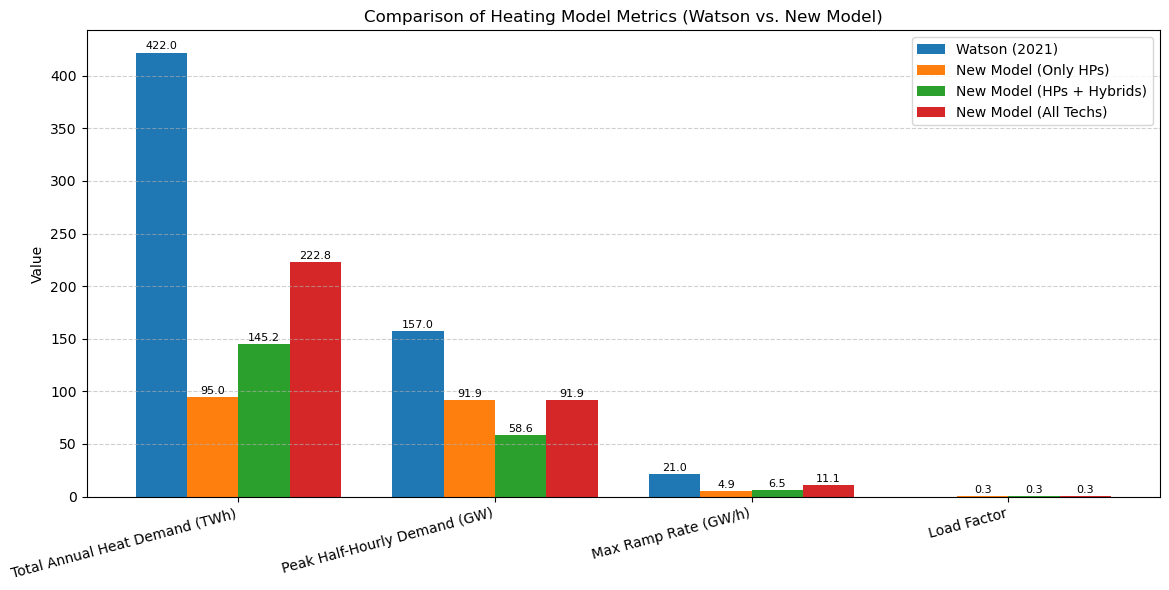

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Categories and models
metrics = ['Total Annual Heat Demand (TWh)', 
           'Peak Half-Hourly Demand (GW)', 
           'Max Ramp Rate (GW/h)', 
           'Load Factor']
models = ['Watson (2021)', 'New Model (Only HPs)', 'New Model (HPs + Hybrids)', 'New Model (All Techs)']

# Data
data = [
    [422, 95.02, 145.22, 222.77],     # Total Demand
    [157, 91.88, 58.56, 91.88],       # Peak Demand
    [21, 4.91, 6.52, 11.14],          # Ramp Rate
    [0, 0.298, 0.283, 0.2767]         # Load Factor (Watson has no value)
]

# Plot setup
x = np.arange(len(metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 6))
bars = []

for i in range(len(models)):
    bars.append(
        ax.bar(x + i*width, [row[i] for row in data], width, label=models[i])
    )

# Labels and legend
ax.set_ylabel('Value')
ax.set_title('Comparison of Heating Model Metrics (Watson vs. New Model)')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics, rotation=15, ha='right')
ax.legend()

# Add value labels
for bar_group in bars:
    for bar in bar_group:
        yval = bar.get_height()
        if yval != 0:
            ax.text(bar.get_x() + bar.get_width() / 2, yval + 1, f'{yval:.1f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


In [40]:
os.getcwd()


'c:\\Users\\s2583817\\OneDrive - University of Edinburgh\\Documents\\Projects\\PhD_Project\\Python\\GB_Residential_Heating'

In [38]:
dwelling_df = pd.read_csv("../data/LA_UK/new_version/gird_square_heat_demand.csv")

<>:1: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\P'
C:\Users\s2583817\AppData\Local\Temp\ipykernel_17388\525331581.py:1: SyntaxWarning: invalid escape sequence '\P'
  dwelling_df = pd.read_csv("C:/Users/s2583817/OneDrive - University of Edinburgh/Documents\Projects/PhD_Project/Python/GB_Residential_Heating/data/A_UK/new_version/gird_square_heat_demand.csv")
C:\Users\s2583817\AppData\Local\Temp\ipykernel_17388\525331581.py:1: SyntaxWarning: invalid escape sequence '\P'
  dwelling_df = pd.read_csv("C:/Users/s2583817/OneDrive - University of Edinburgh/Documents\Projects/PhD_Project/Python/GB_Residential_Heating/data/A_UK/new_version/gird_square_heat_demand.csv")


FileNotFoundError: [Errno 2] No such file or directory: 'C:/Users/s2583817/OneDrive - University of Edinburgh/Documents\\Projects/PhD_Project/Python/GB_Residential_Heating/data/A_UK/new_version/gird_square_heat_demand.csv'